Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g

```python
show_data(get_data())
```

rather than

```python
def show_data():
    get_data()
```

also increases configurability

Terms:

- Class
- Window (w seconds long)
- Shift (s seconds)


In [30]:
%load_ext autoreload
%autoreload 2
# function defs

from functools import partial
from util import *

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-paper')
import matplotlib.ticker as ticker
import yaml
import seaborn as sns
from pandas.io.formats.style import Styler
import subprocess
from weasyprint import HTML, CSS

def typst_table(
    s: Styler, name: str, diag=True, left="s", right="w", index_title=None
):

    display({
        'text/html': s.to_html()
        }, raw=True)


    # pdf export
    def page_rule(y_position: float):
        return f"""
            @page {{
                height: {y_position}px;
            }}
        """
    
    # with open("assets/table.html", "w") as f:
        # f.write(s.to_html())
    html_string = s.to_html() +  '<div id="document-end" />'
    base_css = open("table.css").read()
    # HTML(string=s.to_html()).write_pdf(f"assets/table_{name}.pdf", stylesheets=["table.css"])
    html = HTML(string=html_string)

    test_css = CSS(string=base_css + page_rule(20_000)) # Or some absurd overkill length. Maybe try/catch this if the content could be longer
    test_document = html.render(stylesheets=[test_css])
    target_height = test_document.pages[0].anchors["document-end"][1] # it's a tuple from top-right to bottom left like (x1, y1, x2, y2)

    final_css = CSS(string=base_css + page_rule(target_height))

    html.write_pdf(target=f"assets/table_{name}.pdf", stylesheets=[final_css])
    # subprocess.run(["pandoc", "-o", f"assets/table_{name}.pdf", "-t", ""], input=s.to_html(), text=True)
    # display({'text/plain': s.to_html()})
# TypstStyler = Styler.from_custom_template()

c = Context("../PowerIDS/classifier/power_csv")
with open("common.yml") as f:
    config = yaml.safe_load(f)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
# | label: safenetiot

exp = Experiment(
    c,
    [State.IDLE, State.ACTIVE],
    [Metric.MEAN],
    Classifier.Centroid,
    config["w"],
    config["s"],
)
nice_cats = ["Lights", "Audio", "Camera", "TV", "Appliance"]
categories = {cat: [] for cat in c.categories}
for dev in exp.devices:
    categories[dev.category].append(dev)
# print(categories)
categories = {nice_cats[i]: pd.Series(l) for i, l in enumerate(categories.values())}

typst_table(
    pd.DataFrame(data=categories).fillna("").style.hide(axis="index"), "categories"
)

Lights,Audio,Camera,TV,Appliance
Antela Light,Bose Speaker,Amcrest Camera,Apple TV,Cosori Air Fryer
Fitop Light,Echo Dot 5 Speaker,Blurams Camera,LG TV,Honeywell Thermostat
LIFX Light,Echo Spot 5 Speaker,Boifun Baby Camera,"Samsung 32"" TV",Levoit Air Purifier
Lepro Light,Google Home Speaker,Google Nest Camera,Samsung Small TV,Swan Smart Kettle
Tapo Light,Homepod Speaker,Hualai Camera,TCL TV,Weekett Kettle
Wiz Light,Nest Mini 2 Speaker,Yi Camera,Toshiba TV,Xiaomi Blender
Yeelight Light,Sonos Speaker,,,


In [39]:
# | label: summary

common = partial(
    Experiment, c, classify_by=Classifier.Median, w=config["w"], s=config["s"]
)

summary_idle_mean = common([State.IDLE], [Metric.MEAN])

summary_active_mean = common([State.ACTIVE], [Metric.MEAN])

summary_idle_mean_std = common([State.IDLE], [Metric.MEAN, Metric.STD])

summary_active_mean_std = common([State.ACTIVE], [Metric.MEAN, Metric.STD])
mean_fancy = Metric.MEAN.fancy_name()
std_fancy = Metric.STD.fancy_name()

scores = pd.DataFrame(
    data={
        f"Idle by {mean_fancy}": summary_idle_mean.f1_scores.values(),
        f"Idle by {mean_fancy}, {std_fancy}": summary_idle_mean_std.f1_scores.values(),
        f"Active by {mean_fancy}": summary_active_mean.f1_scores.values(),
        f"Active by {mean_fancy}, {std_fancy}": summary_active_mean_std.f1_scores.values(),
    },
    index=exp.devices,
)
scores["removeme"] = scores.sum(axis=1)
scores = scores.sort_values(by="removeme", ascending=False)
scores = scores.drop("removeme", axis=1)
scores.loc["Macro Average"] = [
    summary_idle_mean.f1_macro_average,
    summary_idle_mean_std.f1_macro_average,
    summary_active_mean.f1_macro_average,
    summary_active_mean_std.f1_macro_average,
]

scores.columns.name = "IoT Device"
typst_table(scores.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1), "summary")

IoT Device,Idle by μ,"Idle by μ, σ",Active by μ,"Active by μ, σ"
Amcrest Camera,1.000000,1.000000,1.000000,1.000000
Yi Camera,1.000000,1.000000,1.000000,1.000000
Samsung Small TV,1.000000,1.000000,0.857143,1.000000
Nest Mini 2 Speaker,1.000000,1.000000,0.857143,1.000000
Cosori Air Fryer,1.000000,1.000000,1.000000,0.857143
"Samsung 32"" TV",1.000000,1.000000,0.857143,1.000000
Levoit Air Purifier,1.000000,1.000000,0.923077,0.923077
Boifun Baby Camera,0.933333,0.875000,1.000000,1.000000
Tapo Light,0.933333,1.000000,0.857143,1.000000
LG TV,1.000000,1.000000,0.857143,0.923077


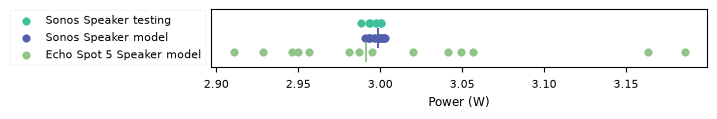

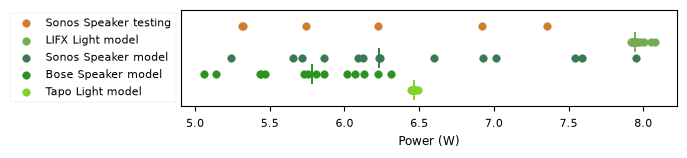

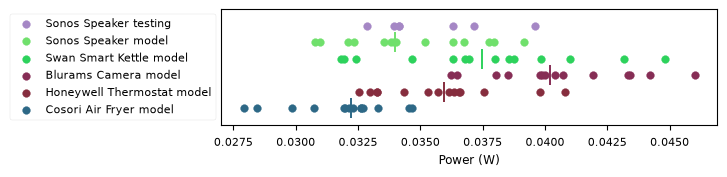

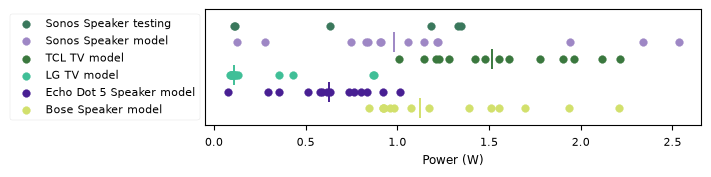

In [61]:
# | label: confused with

# for a device, see what other devices it is confused with
# [ for device, class_ in all.classes.items() if class]


# lifx = all.devices[2]
# 1 function for getting data either training or otherwise to plot.


# 1 function to actually plot it
def confused_with(exp: Experiment, name: str, state: State) -> list[Datum]:
    # return training datums that are confused with the device, and the devices training and testing datums.
    device = exp.get_device(name)
    combo = (device, state)
    selected_data = exp.get_data(*combo)
    confused = list(exp.classes[combo].keys())
    datums = [exp.get_data(*c).training for c in confused]
    if combo not in confused:
        datums = [selected_data.training] + datums

    # TODO: ensure device is first
    datums = [selected_data.testing] + datums
    return datums


def plot_metrics(exp: Experiment, to_plot: list[Datum], log_scale=False):
    if len(exp.metrics) > 1:
        raise ValueError

    fig, ax = plt.subplots()

    n = len(to_plot)
    for i, datum in enumerate(to_plot):
        metric = [profile[exp.metrics[0]] for profile in datum.profile]
        colour = ColorHash((datum)).hex
        ax.scatter(
            metric,
            [n - i] * len(datum.profile),
            label=f"{datum.data.device.name()} {datum.type}",
            c=colour,
        )
        if datum.type == DatumType.TRAINING:
            ax.scatter(np.median(metric), n - i, marker="|", c=colour, s=200)
    if log_scale:
        ax.set_xscale("log")

    ax.set_ylim((0, n + 1))
    ax.legend(loc="center right", bbox_to_anchor=(0, 0.5))
    ax.set_yticks([])
    fig.set_figheight(n / 4)

    ax.set_xlabel("Power (W)")


plot_metrics(summary_idle_mean, confused_with(summary_idle_mean, "sonos", State.IDLE))

plot_metrics(
    summary_active_mean, confused_with(summary_active_mean, "sonos", State.ACTIVE)
)

# TODO mode to plot overlapping distributions
# TODO randomly selected windows, are there startup effects?

std_idle = common([State.IDLE], [Metric.STD])
std_active = common([State.ACTIVE], [Metric.STD])
plot_metrics(std_idle, confused_with(std_idle, "sonos", State.IDLE))

plot_metrics(std_active, confused_with(std_active, "sonos", State.ACTIVE))
plt.show()

0.7934259633340516
0.915438727938728


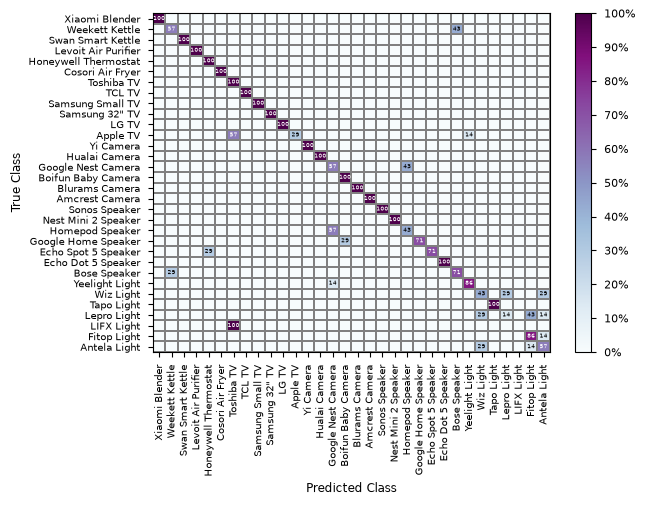

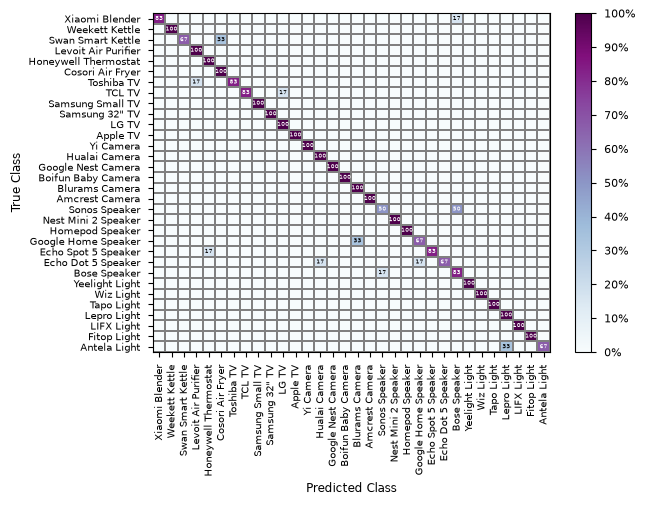

In [62]:
# | label: mu sigma

mu_sigma = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    config["w"],
    config["s"],
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

mu_sigma = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN, Metric.STD],
    Classifier.Median,
    config["w"],
    config["s"],
)

graph_confusion_matrix(mu_sigma)
print(mu_sigma.f1_macro_average)

State,Macro Average F1 score,Devices with precision > 90%
Idle,0.717,19 / 32
Average,0.857,21 / 32


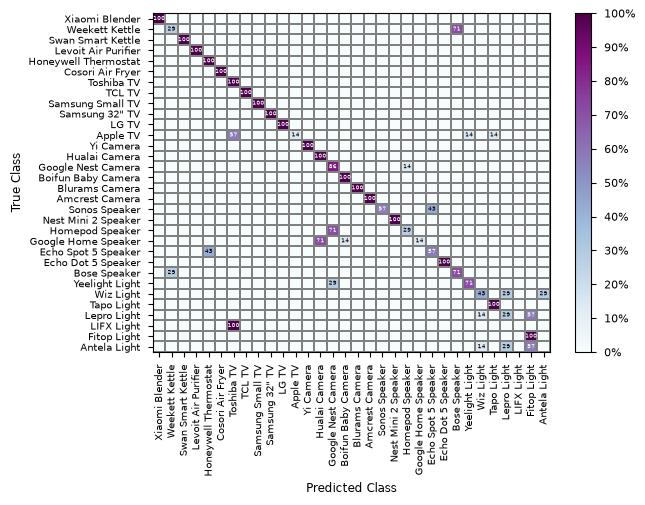

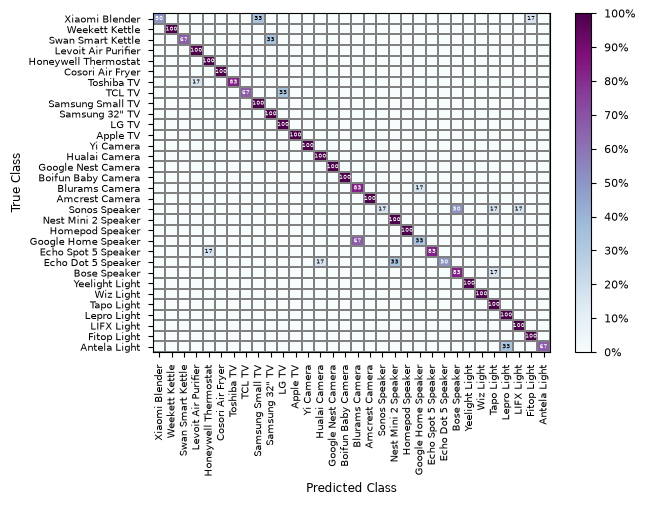

In [ ]:
# | label: confusion matrix
idle = Experiment(
    c,
    [State.IDLE],
    [Metric.MEAN],
    Classifier.Median,
    config["w"],
    config["s"],
)
graph_confusion_matrix(idle)

active = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN],
    Classifier.Median,
    config["w"],
    config["s"],
)
graph_confusion_matrix(active)
mean = pd.DataFrame(
    data={
        "Macro Average F1 score": [idle.f1_macro_average, active.f1_macro_average],
        "Devices with Precision > 90%": [
            f"{len([score for score in idle.precision.values() if score >= 0.9])} / {len(idle.devices)}",
            f"{len([score for score in active.precision.values() if score >= 0.9])} / {len(active.devices)}",
        ],
    },
    index=["Idle", "Average"],
)
mean.columns.name = "State"
typst_table(
    mean.style.format(precision=3),
    "mean",
)
plt.show()

Wrote graph to assets/confusion-matrix-idle-300-120-fft-Median.pdf
Wrote graph to assets/confusion-matrix-active-300-120-mean-fft-Median.pdf


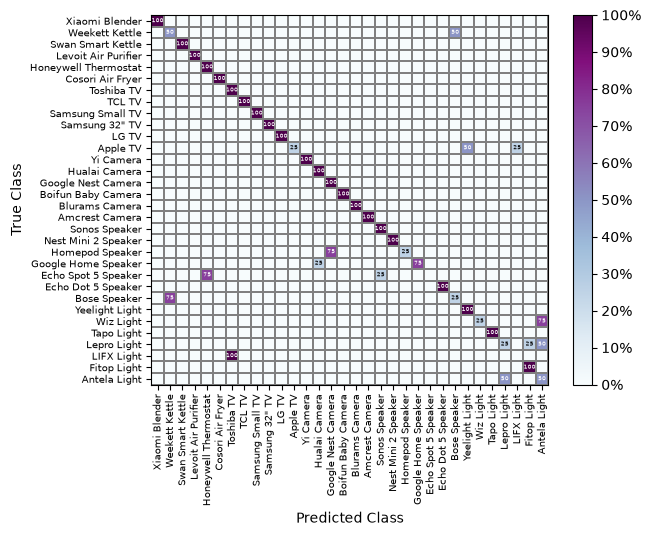

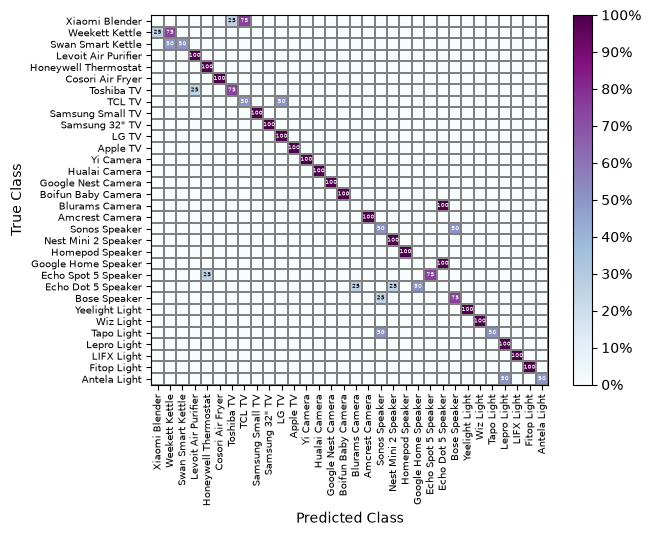

In [ ]:
# | label: fft

fft = Experiment(
    c,
    [State.IDLE],
    [Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft)

fft_both = Experiment(
    c,
    [State.ACTIVE],
    [Metric.MEAN, Metric.FFT],
    Classifier.Median,
    300,
    120,
)

graph_confusion_matrix(fft_both)

In [71]:
# | label: combined

both = Experiment(
    c,
    states=[State.IDLE, State.ACTIVE],
    metrics=[Metric.MEAN],
    classify_by=Classifier.Median,
    w=config["w"],
    s=config["s"],
)

both.f1_macro_average

# accuracy at picking state, assumes only 2 states

state = {state: 0.0 for state in State}
for (_, real_state), counter in both.classes.items():
    sum = 0
    for (_, predicted_state), count in counter.items():
        if predicted_state == real_state:
            sum += count

    state[real_state] += sum / counter.total() / len(both.devices)
    # distributive
both = pd.DataFrame(data=state, index=["Macro Average F1 Score"])
both.columns = both.columns.str.capitalize()
typst_table(
    both.style.format(precision=3),
    "both",
)

# graph_confusion_matrix(both)

,Active,Idle
Macro Average F1 Score,0.859,0.937
